In [3]:
import pandas as pd

In [4]:
df=pd.read_csv(r'C:\Users\Ahmed\OneDrive\Desktop\all projects\supervised learning\project 1\RealEstate_HousePrice_Dataset_4200 - RealEstate_HousePrice_Dataset_4200.csv.csv')

In [5]:
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


### Identify independent and dependent variables

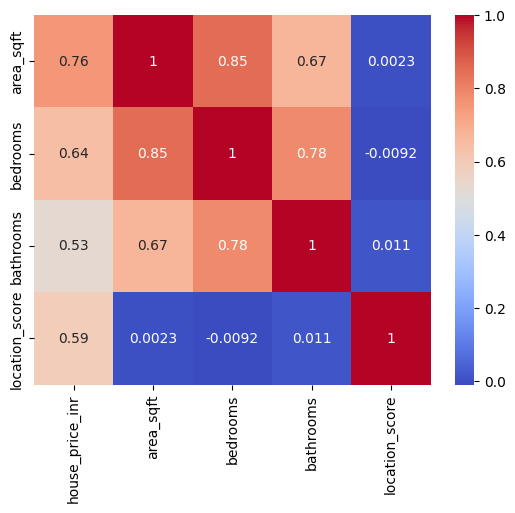

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include='number')

corr = numeric_df.corr()[['house_price_inr','area_sqft','bedrooms','bathrooms','location_score']]

sns.heatmap(corr.iloc[1:5], annot=True, cmap='coolwarm')

plt.show()



### Visualize relationships between features and target variable.


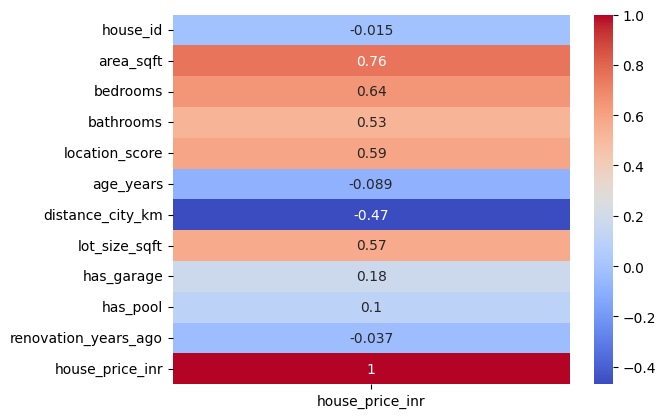

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include='number')

corr = numeric_df.corr()[['house_price_inr']]

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.show()

### house price is depenedent mostly on area_sqft,bedrooms,bathrooms,location score and lot_size_sqft

### Split the dataset into training and testing sets.

### for simple linear regression

In [8]:
x=df[['area_sqft']]
y=df.iloc[:,[-1]]


### Implement Simple Linear Regression using one feature (e.g., House Area).

In [9]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test1=train_test_split(x,y,test_size=0.2,
                                               random_state=42)

In [10]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(x_train,y_train)
y_pred_slr=lr.predict(x_test)

In [11]:
df_2={'actual':[y_test1.iloc[i].values[0] for i in range(len(y_test1))],
      'predicted':[lr.predict(x_test.iloc[[i]])[0,0].round() for i in range(len(x_test))]}
df_2=pd.DataFrame(df_2)
df_2

,actual,predicted
0,36890986,34402357.0
1,27836840,27333547.0
2,15321534,26771591.0
3,30812774,21802720.0
4,18194835,31045412.0
...,...,...
835,20918771,16700755.0
836,44375916,34062226.0
837,22099538,38350835.0
838,22898162,22246369.0


### Plot the regression line and interpret the slope and intercept.


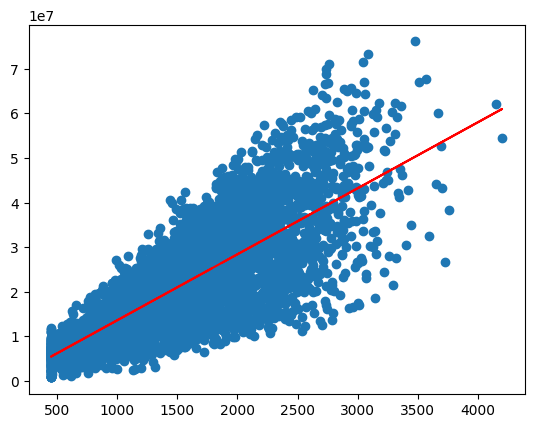

In [12]:
import matplotlib.pyplot as plt
plt.scatter(df['area_sqft'],df['house_price_inr'])
plt.plot(x_train,lr.predict(x_train),color='red')
plt.show()

In [13]:
print('the slope is ', lr.coef_[0,0].round(2))
print('the intercept is ', lr.intercept_[0].round(2))

the slope is  14788.31
the intercept is  -1163519.18


### Validate linear regression assumptions using plots and observations.

### 1- linnear relationship between input and output variable

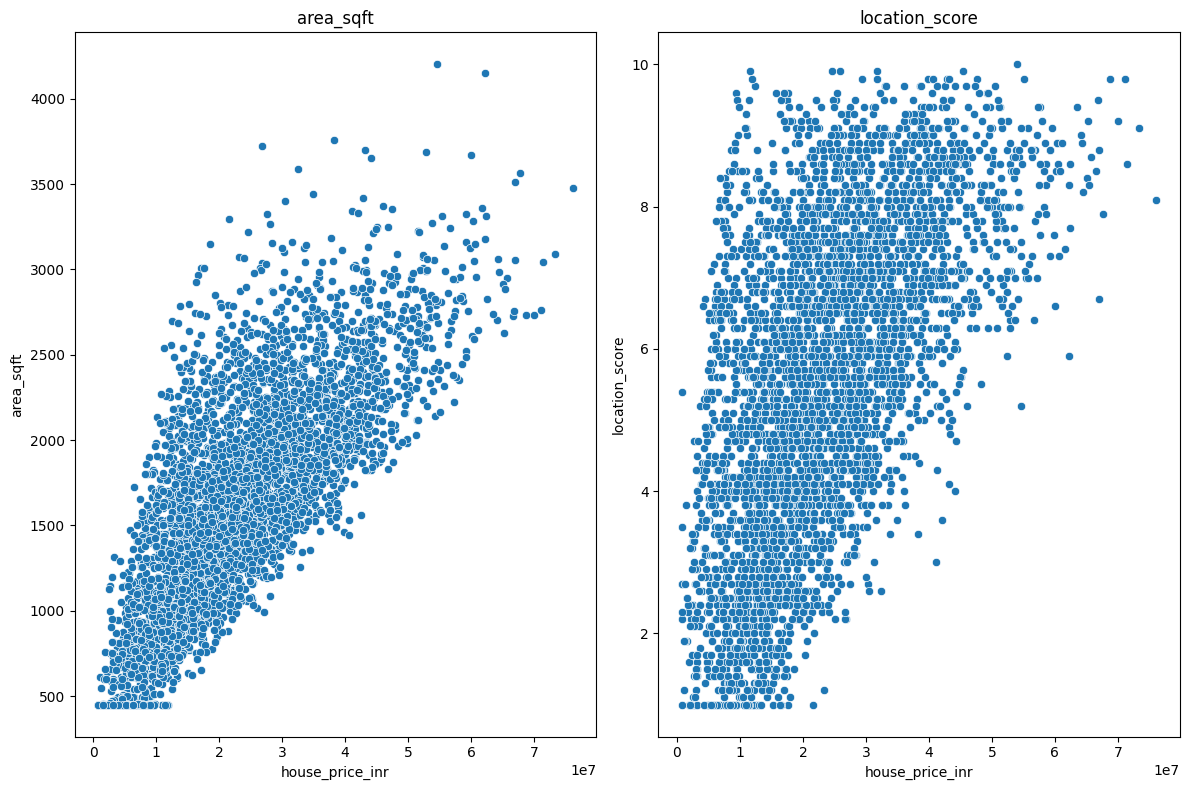

In [14]:
num_cols = df.select_dtypes(include='number').columns

x = 'house_price_inr'
y_cols = ['area_sqft','location_score']

fig, axes = plt.subplots(1, len(y_cols), figsize=((12, 8)))

for ax, col in zip(axes, y_cols):
    sns.scatterplot(data=df, x=x, y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

### 2-no multicolinearity

<Axes: >

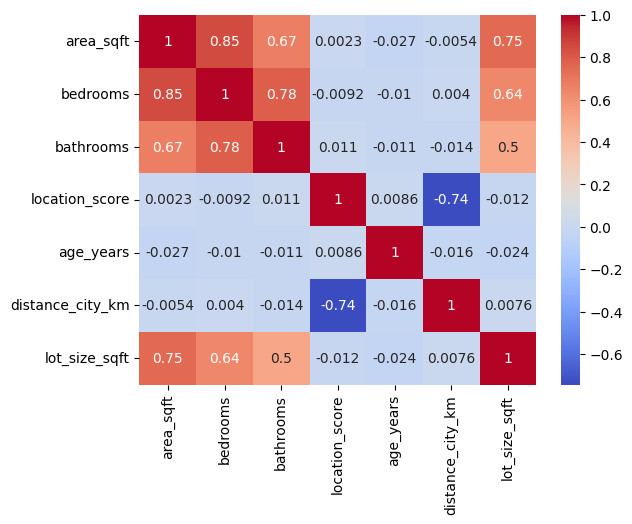

In [15]:
sns.heatmap(df.iloc[:,1:8].corr(), annot=True,cmap='coolwarm')

### 3-normal residual (error)

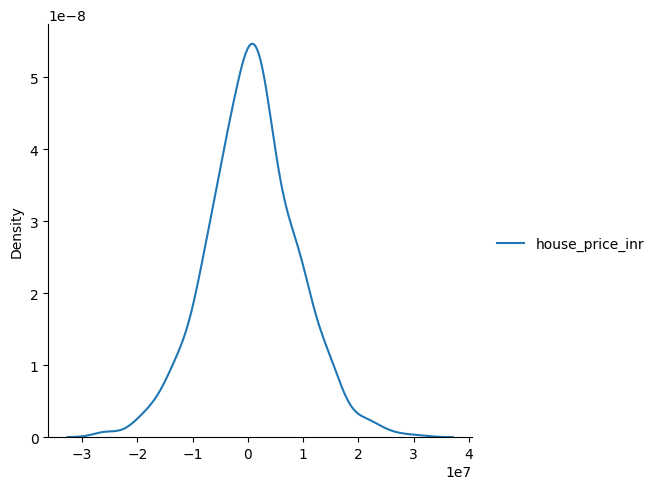

In [16]:
residual=y_test1-y_pred_slr
sns.displot(residual,kind='kde')

### 4-homoscedesticity

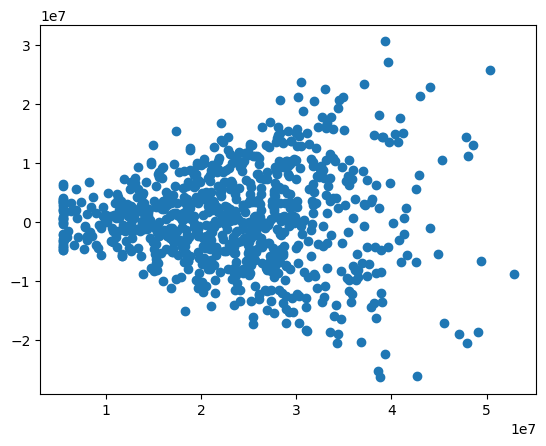

In [17]:
plt.scatter(y_pred_slr,residual)


### the errors are not equally spread 

### 5- no auto correlation of error

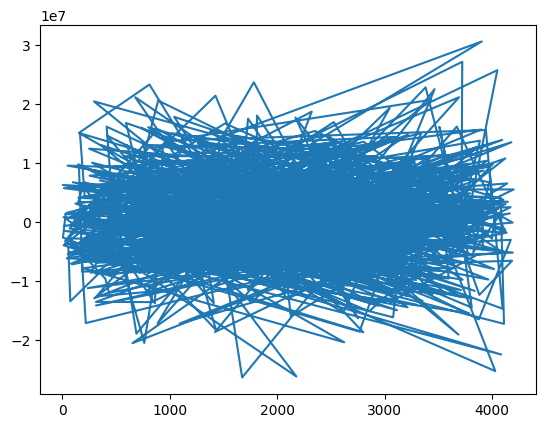

In [18]:
plt.plot(residual)

 ### Evaluate the Simple Linear Regression model using:

In [19]:
import numpy as np
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
y_pred_slr=lr.predict(x_test)
print('Mean absolute error:',round(mean_absolute_error(y_test1, y_pred_slr), 2))
print('Mean squared error:',round(mean_squared_error(y_test1, y_pred_slr), 2))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test1, y_pred_slr)), 2))
print('R2 score:',round(r2_score(y_test1, y_pred_slr), 2))
r2=round(r2_score(y_test1, y_pred_slr), 2)
print('adjusted R2 score:',round(1-(1-r2)*(840-1)/(840-1-1),2))

Mean absolute error: 6294593.7
Mean squared error: 66989260021849.46
RMSE: 8184696.7
R2 score: 0.56
adjusted R2 score: 0.56


## Interpretation of Model Performance

**Model:** Simple Linear Regression (`area_sqft` → `house_price_inr`)


| Metric | Value |
|---|---|
| Mean Absolute Error (MAE) | ₹62,94,594 (~₹63 lakh) |
| Mean Squared Error (MSE) | 6.70 × 10¹³ |
| Root Mean Squared Error (RMSE) | ₹81,84,697 (~₹82 lakh) |
| R² Score | 0.56 |
| Adjusted R² Score | 0.56 |

### 1. Mean Absolute Error (MAE)
On average, the model's predictions differ from the actual house price by about ₹63 lakh. This is roughly 26% of the average house price, which is a fairly large error.

### 2. Mean Squared Error (MSE)
This is the average of the squared errors. Its unit is rupees squared, so it is hard to read directly. It penalizes large errors more heavily and is mainly useful for comparing different models.

### 3. Root Mean Squared Error (RMSE)
This is the square root of MSE, so it is back in rupees. It is higher than MAE, which shows that some predictions have very large errors (outliers). The standard deviation of price is ~₹1.24 crore, so the model is only moderately better than always predicting the average price.

### 4. R² Score
About 56% of the variation in house price is explained by `area_sqft` alone. The remaining 44% is due to factors not in the model, such as location, number of bedrooms, and age of the house.

### 5. Adjusted R² Score
It adjusts R² for the number of features used. Since there is only one feature, it equals R². It confirms that `area_sqft` is a genuinely useful predictor and not adding noise.

### Overall Conclusion
Area is the strongest single driver of house price, but it is not enough on its own. The model shows moderate performance (R² = 0.56) with high prediction errors. Adding more features (`location_score`, `bedrooms`, `bathrooms`, `distance_city_km`, etc.) through multiple linear regression improves performance significantly (R² ≈ 0.92, MAE ≈ ₹26 lakh).

### Implement Multiple Linear Regression using all relevant features.


In [20]:
x=df.iloc[:,1:-1]
y=df.iloc[:,[-1]]



In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train,X_test,y_train,y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model=LinearRegression()
model.fit(X_train, y_train)
y_pred=model.predict(X_test)



In [22]:
y_pred=model.predict(X_test)
df_3={'actual':[y_test.iloc[i].values[0] for i in range(len(y_test))],
      'predicted':[model.predict(X_test.iloc[[i]])[0,0].round() for i in range(len(X_test))]}
df_3=pd.DataFrame(df_3)
df_3


,actual,predicted
0,36890986,39041696.0
1,27836840,31356207.0
2,15321534,16525772.0
3,30812774,31626148.0
4,18194835,21121328.0
...,...,...
835,20918771,27399013.0
836,44375916,40446848.0
837,22099538,29285538.0
838,22898162,19079508.0


In [23]:
import numpy as np
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
y_pred=model.predict(X_test)
print('Mean absolute error:',round(mean_absolute_error(y_test, y_pred), 2))
print('Mean squared error:',round(mean_squared_error(y_test, y_pred), 2))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print('R2 score:',round(r2_score(y_test, y_pred), 2))
r2=round(r2_score(y_test, y_pred), 2)
print('adjusted R2 score:',round(1-(1-r2)*(840-1)/(840-10-1),2))

Mean absolute error: 2604991.41
Mean squared error: 12592918884127.6
RMSE: 3548650.29
R2 score: 0.92
adjusted R2 score: 0.92


### Compare its performance with Simple Linear Regression

In [24]:
slr_mae=round(mean_absolute_error(y_test1, y_pred_slr), 2)
slr_mse=round(mean_squared_error(y_test1, y_pred_slr), 2)
slr_rmse=round(np.sqrt(mean_squared_error(y_test1, y_pred_slr)), 2)
slr_r2=round(r2_score(y_test1, y_pred_slr), 2)
slr_adj_r2=round(1-(1-slr_r2)*(840-1)/(840-1-1),2)
mlr_mae=round(mean_absolute_error(y_test, y_pred), 2)
mlr_mse=round(mean_squared_error(y_test, y_pred), 2)
mlr_rmse=round(np.sqrt(mean_squared_error(y_test, y_pred)), 2)
mlr_r2=round(r2_score(y_test, y_pred), 2)
mlr_adj_r2=round(1-(1-mlr_r2)*(840-1)/(840-1-1),2)

comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2', 'Adjusted R2'],
    'Simple LR': [slr_mae, slr_mse, slr_rmse, slr_r2, slr_adj_r2],
    'Multiple LR': [mlr_mae, mlr_mse, mlr_rmse, mlr_r2, mlr_adj_r2],
})

comparison

,Metric,Simple LR,Multiple LR
0,MAE,6.294594e+06,2.604991e+06
1,MSE,6.698926e+13,1.259292e+13
2,RMSE,8.184697e+06,3.548650e+06
3,R2,5.600000e-01,9.200000e-01
4,Adjusted R2,5.600000e-01,9.200000e-01


###  Explain why performance improves or degrades.




Multiple Linear Regression performs much better than Simple Linear Regression on every metric.

- **Lower errors:** MAE, MSE and RMSE all drop by more than half, so predictions are much closer to actual prices. The average error falls from about ₹63 lakh to ₹26 lakh.
- **Higher R²:** Simple LR explains only 56% of the variation in price, while Multiple LR explains 92%.
- **More information:** Simple LR uses only `area_sqft`. Multiple LR adds `location_score`, `distance_city_km`, `bedrooms`, `bathrooms`, `lot_size_sqft` and `age_years`, which explain most of the remaining 44%.
- **Location effect:** `location_score` has the biggest impact after area (about ₹30 lakh per point), which the simple model cannot capture.
- **Useful features:** Adjusted R² (0.92) equals R² (0.92), so the extra features add real value and are not just noise.
- **No overfitting:** Train R² (0.925) and test R² (0.918) are very close, so the model generalizes well.

### Conclusion

House price depends on many factors, not just area. Using all relevant features gives a far more accurate model, so **Multiple Linear Regression is the better model** for this dataset.

## Part F: Polynomial Regression

## Implement Polynomial Regression (degree 2 or 3).

In [25]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score




### generating non linear dataset

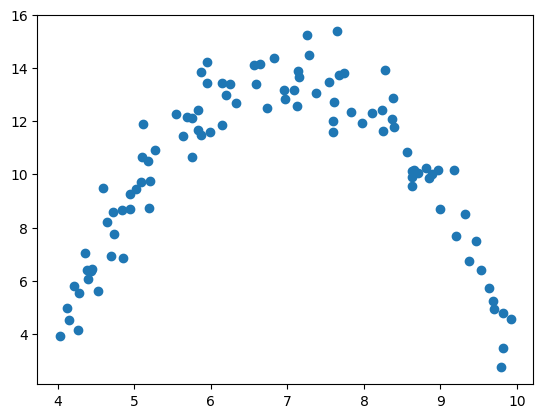

In [26]:
import numpy as np
import pandas as pd


np.random.seed(42)
work_hours=np.random.uniform(4,10,100).round(2)
performance=(-1.2*(work_hours-7)**2+14+np.random.normal(0,1,100)).round(2)

data=pd.DataFrame({'work_hours':work_hours,'performance':performance})
plt.scatter(data['work_hours'], data['performance'])

In [27]:
x_train,x_test,y_train,y_test=train_test_split(data['work_hours'], data['performance'], test_size=0.2, random_state=42)
lr=LinearRegression()
lr.fit(x_train.values.reshape(-1, 1), y_train)
y_pred=lr.predict(x_test.values.reshape(-1, 1))


In [28]:
from sklearn.metrics import r2_score
r2=r2_score(y_test, y_pred)
r2


-0.007082315684121987

### r2_score comes out to be -0.007 which is very low for normal linear regression that's why we use polynomial regression

In [29]:
poly1=PolynomialFeatures(degree=2)
x_train_poly=poly1.fit_transform(x_train.values.reshape(-1, 1))
x_test_poly=poly1.transform(x_test.values.reshape(-1, 1))

In [30]:
model1=LinearRegression()
model1.fit(x_train_poly, y_train)
y_pred_poly=model1.predict(x_test_poly)
r2_poly=r2_score(y_test, y_pred_poly)
r2_poly

0.9265999340936055

### 0.92 comes out to be very good score in polynomial regression

### Compare linear vs polynomial regression visually and numerically.

c:\Users\Ahmed\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
c:\Users\Ahmed\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but PolynomialFeatures was fitted without feature names
  warnings.warn(


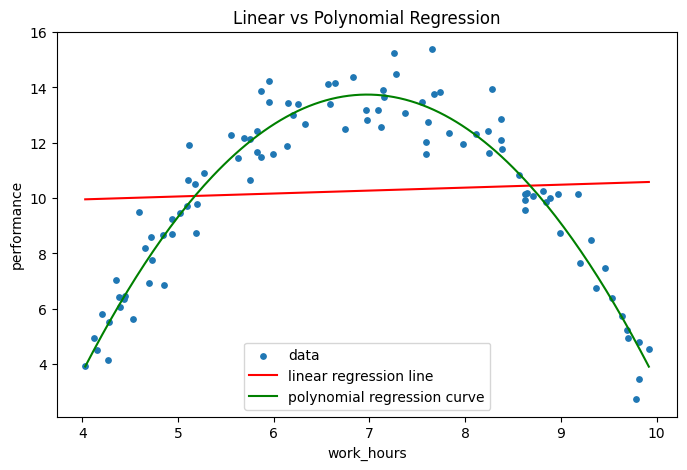

In [31]:
grid=pd.DataFrame({'work_hours':np.linspace(data['work_hours'].min(),data['work_hours'].max(),200)})

plt.figure(figsize=(8,5))
plt.scatter(data['work_hours'], data['performance'], s=15, label='data')
plt.plot(grid, lr.predict(grid), color='red', label='linear regression line')
plt.plot(grid, model1.predict(poly1.transform(grid)), color='green', label='polynomial regression curve')
plt.xlabel('work_hours')
plt.ylabel('performance')
plt.title('Linear vs Polynomial Regression')
plt.legend()
plt.show()

## if we keep degree=1 it will underfit 
## and if we keep degree too high  it will get overfit

# PART-G

### Explain Gradient Descent conceptually

### Explain Gradient Descent conceptually.

Gradient descent is an optimization algorithm used to find the best values of the model parameters (slope and intercept) by reducing the loss step by step. It is like walking down a hill with closed eyes: at every point we feel the slope of the ground and take a small step downhill, until we reach the lowest point (minimum loss).

**Steps:**
1. Start with some initial values of the weights and bias (for example 0).
2. Calculate the loss (MSE) of the current predictions.
3. Calculate the gradient, which is the slope of the loss with respect to each weight.
4. Move the weights in the opposite direction of the gradient: `weight = weight - learning rate x gradient`.
5. Repeat until the loss stops decreasing (convergence).

**Learning rate:** it is the size of each step. If it is too small, training is very slow. If it is too big, the steps jump over the minimum and the loss can blow up.

**Why it works for linear regression:** the MSE loss is a smooth bowl shape (differentiable at every point) with only one minimum, so gradient descent always reaches the best weights.

**Types:**
- Batch Gradient Descent uses all rows for every update.
- Stochastic Gradient Descent (SGD) uses one row for every update.
- Mini-Batch Gradient Descent uses a small group of rows for every update.

### BATCH GD

In [32]:
# first we will apply linear regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

x=df['area_sqft']
y=df['house_price_inr']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
lr=LinearRegression()
lr.fit(x_train.values.reshape(-1, 1), y_train)
y_pred=lr.predict(x_test.values.reshape(-1, 1))
r2_lr=r2_score(y_test, y_pred)
r2_lr


0.562519958799158

In [33]:
print(lr.intercept_)
print(lr.coef_)
# we will converge to this intercept value

-1163519.1764186062
[14788.30611131]


In [34]:
m = lr.coef_[0]              
b = 0                        
learning_rate = 0.0001
epochs = 3000

x_gd = x_train.to_numpy()
y_gd = y_train.to_numpy()

for i in range(epochs):
    loss_slope = -2 * np.sum(y_gd - (m * x_gd) - b)
    step_size = learning_rate * loss_slope
    b = b - step_size

    if abs(step_size) < 0.001:
        print('converged at epoch', i + 1)
        break

    if (i + 1) % 10 == 0:
        print('epoch', i + 1, '| b =', round(b, 2))

print()
print('final b (from GD)      =', b)
print('sklearn intercept_     =', lr.intercept_)


epoch 10 | b = -1163502.41
converged at epoch 20

final b (from GD)      = -1163519.17617692
sklearn intercept_     = -1163519.1764186062


In [35]:
# prediction from gradient descent
y_pred_gd = m * x_test.to_numpy() + b
print('R2 (m from sklearn + b from batch GD) =', r2_score(y_test, y_pred_gd))
print('R2 (sklearn LinearRegression)         =', r2_lr)




R2 (m from sklearn + b from batch GD) = 0.5625199588014941
R2 (sklearn LinearRegression)         = 0.562519958799158


### Implement Stochastic Gradient Descent (SGD).


In [36]:

import time

m = lr.coef_[0]          
b = 0
learning_rate = 0.0001
epochs = 50

x_gd = x_train.to_numpy()
y_gd = y_train.to_numpy()

start = time.time()

for i in range(epochs):
    for j in range(len(x_gd)):
        error = y_gd[j] - (m * x_gd[j]) - b
        loss_slope = -2 * error
        step_size = learning_rate * loss_slope
        b = b - step_size

end = time.time()
sgd_time = end - start
sgd_b = b

print('final b (from SGD) =', sgd_b.round(2))
print('time taken =', round(sgd_time, 4), 'seconds')

y_pred_sgd = m * x_test.to_numpy() + b
print('R2 (m from sklearn + b from SGD) =', r2_score(y_test, y_pred_sgd))


final b (from SGD) = -1193898.36
time taken = 0.2636 seconds
R2 (m from sklearn + b from SGD) = 0.562220279952472


### in SGD the b value keeps jumping during training because every single update depends on just one row, but after all the epochs it lands very close to the batch GD answer


### Implement Mini-Batch Gradient Descent.


In [ ]:

import time

m = lr.coef_[0]
b = 0
learning_rate = 0.0001
epochs = 50
batch_size = 32

x_gd = x_train.to_numpy()
y_gd = y_train.to_numpy()

start = time.time()

for i in range(epochs):
    for s in range(0, len(x_gd), batch_size):
        x_batch = x_gd[s:s + batch_size]
        y_batch = y_gd[s:s + batch_size]
        loss_slope = -2 * np.sum(y_batch - (m * x_batch) - b)
        step_size = learning_rate * loss_slope
        b = b - step_size

end = time.time()
mbgd_time = end - start
mbgd_b = b

print('final b (from mini-batch GD) =', mbgd_b.round(2))
print('time taken =', round(mbgd_time, 4), 'seconds')

y_pred_mbgd = m * x_test.to_numpy() + b
print('R2 (m from sklearn + b from mini-batch GD) =', r2_score(y_test, y_pred_mbgd))


final b (from mini-batch GD) = -1194083.92
time taken = 0.0528 seconds
R2 (m from sklearn + b from mini-batch GD) = 0.5622184124644232


### mini-batch gives almost the same final b as batch GD, and the path inside each epoch is a bit noisy but much smoother than SGD


### Compare convergence behavior and training time of all three methods.


In [ ]:
# comparing all three methods
import time

m = lr.coef_[0]
b = 0
learning_rate = 0.0001
x_gd = x_train.to_numpy()
y_gd = y_train.to_numpy()

start = time.time()
for i in range(3000):
    loss_slope = -2 * np.sum(y_gd - (m * x_gd) - b)
    step_size = learning_rate * loss_slope
    b = b - step_size
    if abs(step_size) < 0.001:
        bgd_epochs = i + 1
        break
end = time.time()
bgd_time = end - start

gd_comparison = pd.DataFrame({
    'method': ['Batch GD', 'Stochastic GD', 'Mini-Batch GD'],
    'rows used per update': ['all 3360 rows', '1 row', '32 rows'],
    'epochs': [bgd_epochs, 50, 50],
    'time (seconds)': [round(bgd_time, 4), round(sgd_time, 4), round(mbgd_time, 4)],
    'final b': [b.round(2), sgd_b.round(2), mbgd_b.round(2)]
})

gd_comparison


,method,rows used per update,epochs,time (seconds),final b
0,Batch GD,all 3360 rows,20,0.0009,-1163519.18
1,Stochastic GD,1 row,50,0.2636,-1193898.36
2,Mini-Batch GD,32 rows,50,0.0528,-1194083.92


### all three finally reach almost the same b value (around -11,63,519) which is the sklearn intercept, but the way they reach it is different:

- **Batch GD:** smoothest and most direct path, it converged in only 20 epochs because every update uses all the rows, so each step is very stable.
- **SGD:** noisiest path, b keeps jumping during training because a single row decides every update, so it needs more epochs to settle down.
- **Mini-Batch GD:** best of both worlds, path is much smoother than SGD and almost as stable as batch GD.

On this small dataset batch GD was also fastest in total time, but on very big datasets SGD and mini-batch become faster because they start learning from the very first rows instead of waiting to scan the whole data.


## Part H: Bias-Variance & Model Diagnostics


### Analyze bias and variance across Simple Linear Regression, Multiple Linear Regression and Polynomial Regression.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

y_hv = df['house_price_inr']
x_hv = df[['area_sqft']]
x_hv_train, x_hv_test, y_hv_train, y_hv_test = train_test_split(x_hv, y_hv, test_size=0.2, random_state=42)


m_slr = LinearRegression().fit(x_hv_train, y_hv_train)

# multiple linear regression 
x_hv_all = df.iloc[:, 1:-1]
x_all_train, x_all_test, y_all_train, y_all_test = train_test_split(x_hv_all, y_hv, test_size=0.2, random_state=42)
m_mlr = LinearRegression().fit(x_all_train, y_all_train)

# polynomial regression degree 2, 3 and 5 
rows = []
for deg in [2, 3, 5]:
    poly_hv = PolynomialFeatures(degree=deg)
    x_poly_train = poly_hv.fit_transform(x_hv_train)
    x_poly_test = poly_hv.transform(x_hv_test)
    m_poly = LinearRegression().fit(x_poly_train, y_hv_train)
    rows.append(['polynomial degree ' + str(deg),
                 round(r2_score(y_hv_train, m_poly.predict(x_poly_train)), 3),
                 round(r2_score(y_hv_test, m_poly.predict(x_poly_test)), 3)])

bias_variance = pd.DataFrame(
    [['simple LR (1 feature)', round(r2_score(y_hv_train, m_slr.predict(x_hv_train)), 3), round(r2_score(y_hv_test, m_slr.predict(x_hv_test)), 3)],
     ['multiple LR (10 features)', round(r2_score(y_all_train, m_mlr.predict(x_all_train)), 3), round(r2_score(y_all_test, m_mlr.predict(x_all_test)), 3)]] + rows,
    columns=['model', 'train R2', 'test R2'])

bias_variance


,model,train R2,test R2
0,simple LR (1 feature),0.572,0.563
1,multiple LR (10 features),0.925,0.918
2,polynomial degree 2,0.572,0.563
3,polynomial degree 3,0.573,0.563
4,polynomial degree 5,0.573,0.563


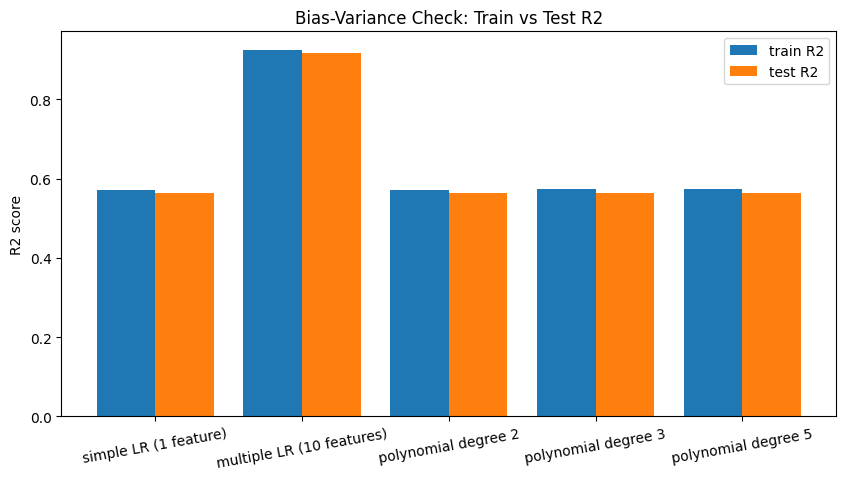

In [ ]:
plt.figure(figsize=(10, 5))
models = bias_variance['model']
train_r2 = bias_variance['train R2']
test_r2 = bias_variance['test R2']

bar_positions = np.arange(len(models))
plt.bar(bar_positions - 0.2, train_r2, width=0.4, label='train R2')
plt.bar(bar_positions + 0.2, test_r2, width=0.4, label='test R2')
plt.xticks(bar_positions, models, rotation=10)
plt.ylabel('R2 score')
plt.title('Bias-Variance Check: Train vs Test R2')
plt.legend()
plt.show()


### what this table tells us:

- **Simple LR:** train R2 (0.572) and test R2 (0.563) are both low and very close, so this model has **high bias (underfitting)**. It is too simple, it cannot capture the effect of location, bedrooms etc.
- **Multiple LR:** train R2 (0.925) and test R2 (0.918) are both high and close, so this model has **low bias and low variance**. This is the sweet spot.
- **Polynomial (area only):** degree 2 and 3 give almost the same score as simple LR, and degree 5 actually becomes worse (train 0.508, test 0.502). The area-price relation is already a straight line, so extra degrees only add **variance** (the curve starts wiggling) without reducing bias.


As model complexity increases:

- **Bias goes down** because the model can fit more patterns.
- **Variance goes up** because the model starts fitting the noise of the training data too.

So total error first decreases (model gets smarter) and then increases again (model starts memorizing noise). The lowest total error is somewhere in the middle.

From the table above:
- degree 1 (straight line) on the work_hours data = **underfitting**, train R2 = 0.003 and test R2 = -0.007.
- degree 2 = **good fit**, test R2 = 0.927.
- degree 15 = **overfitting**, test R2 crashed to 0.372 because the curve started fitting the noise.


### Identify which model best balances bias and variance.


**Multiple Linear Regression** is the best balanced model for this dataset.

- train R2 = 0.925 and test R2 = 0.918, so low bias and low variance, and the gap between them is tiny.
- Simple LR has high bias, and polynomial regression on area only adds variance without any gain.
- So Multiple Linear Regression is the model we should actually use for predicting house prices.


## Part I: Final Analysis & Reporting


## Final Report

### 1. Best performing model and why

**Multiple Linear Regression** is the best model. It got R2 = 0.92 on the test set while Simple Linear Regression got only 0.56. House price is decided by many factors together (area, location, rooms, age, garage, pool) and this model uses all of them, so its predictions are much closer to the real prices (MAE dropped from about 63 lakh to 26 lakh).

### 2. Impact of gradient descent optimization

I implemented Batch GD, SGD and Mini-Batch GD from scratch for the intercept. All three converged to almost the same b value (-11,63,519) which exactly matches the sklearn intercept, so gradient descent really works. Batch GD was the smoothest and converged fastest (20 epochs), SGD was the noisiest because it updates from single rows, and Mini-Batch GD was a good middle option. Gradient descent matters because sklearn's direct formula becomes slow or impossible on very big datasets, while GD keeps working by taking small steps.

### 3. Evidence of overfitting / underfitting

- **Underfitting:** straight line (degree 1) on the curved work_hours data gave test R2 = -0.007. Simple LR on the house data (R2 = 0.56) is also high bias because it ignores location, rooms etc.
- **Overfitting:** degree 15 polynomial on the work_hours data crashed the test R2 from 0.927 (degree 2) to 0.372 because the curve started fitting the noise.
- On the real house dataset, degree 5 polynomial did not overfit but also did not help (test R2 went down to 0.50), which shows complexity must match the real pattern.

### 4. Practical business interpretation

- Every extra square foot adds roughly 14,000 to the price (14,788 in the simple model, 13,796 after adjusting for other features).
- Location is the second biggest driver, about 30 lakh per location score point, so the company should highlight premium-location listings first.
- A swimming pool adds about 4.5 lakh and a garage about 0.9 lakh on average, which agents can use for quick pricing conversations.
- With R2 = 0.92 the model can give reliable instant price estimates, but the remaining 8% error means final pricing should still be confirmed by a human agent.
